In [3]:
%run ./dataManipulation.ipynb

ModuleNotFoundError: No module named 'nbformat'

In [2]:
import seaborn as sns
from scipy import stats

from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder

from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit, GridSearchCV
from sklearn.metrics import f1_score, confusion_matrix, accuracy_score, recall_score, precision_score, precision_recall_curve
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

2024-03-15 18:13:46.391341: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [3]:
columns = ['clipID', 'Extraversion', 'Agreeableness', 'Conscientiousness', 'Neuroticism', 'Openness', 'Gender']
listOfGenders = np.array(metadata)[:,2]
unique_values, counts = np.unique(listOfGenders, return_counts=True)

## Class Imbalance

,Value,Frequency,Percentage
Male,0,503,78.59375
Female,1,137,21.40625


/var/folders/ts/ssvzmj4936s0c7c00wysszg00000gn/T/ipykernel_17079/1032844435.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Gender', data=df, palette=['lightblue', 'darkblue'])


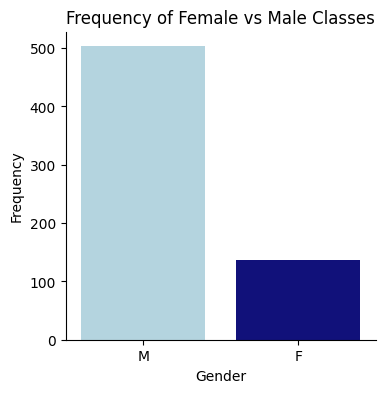

In [4]:
labelencoder=LabelEncoder()
y=to_categorical(labelencoder.fit_transform(listOfGenders))[:,0].astype(int)
# No of men vs no of women

valueCounts = pd.DataFrame(y).value_counts().reset_index()
valueCounts.columns = ['Value', 'Frequency']
valueCounts = valueCounts.rename(index={0: 'Male', 1: 'Female'})
totalClips = valueCounts['Frequency'].sum()
valueCounts['Percentage'] = (valueCounts['Frequency'] / totalClips) * 100
display(Markdown('## Class Imbalance'))
display(valueCounts)


array = np.concatenate((medianScoresPerClip(), listOfGenders.reshape(-1,1)), axis=1)
df = pd.DataFrame(array, columns=columns)
dfMale = df[df.Gender == 'M']
dfFemale = df[df.Gender == 'F']
df = pd.concat([dfMale, dfFemale])
plt.figure(figsize=(4, 4))
sns.countplot(x='Gender', data=df, palette=['lightblue', 'darkblue'])
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.title('Frequency of Female vs Male Classes')
plt.xlabel('Gender')
plt.ylabel('Frequency')
plt.show()




## PCA

Pricipal component variance: [0.35845079 0.29290806]


'Relationship between original features (Big Five) and Principal Components:'

,PC1,PC2
Extraversion,0.602524,-0.157927
Agreeableness,-0.371915,-0.584500
Conscientiousness,0.370081,-0.533504
Neuroticism,0.487827,0.439006
Openness,0.351723,-0.395052


Amount of variance per principal component: [0.35845079 0.29290806 0.15350095 0.10301126 0.09212895]


<Figure size 640x480 with 0 Axes>

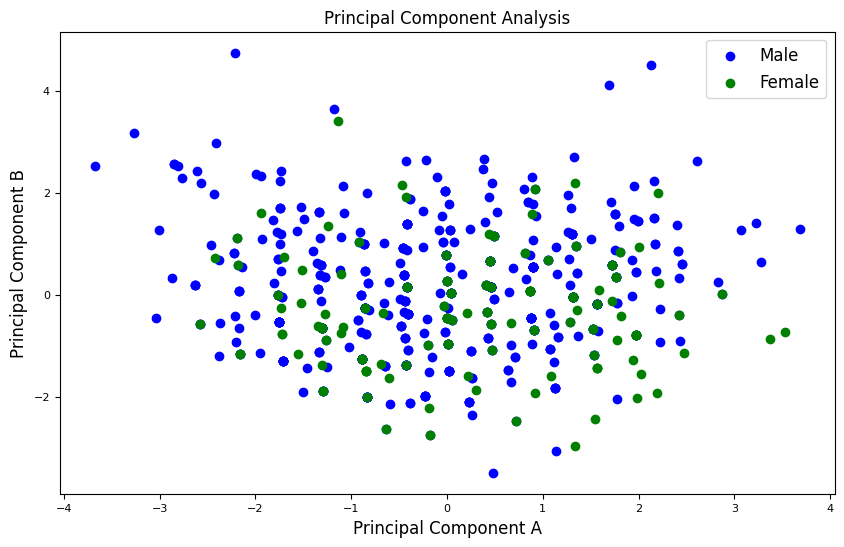

In [5]:
data = medianScoresPerClip()[:,1:]

labels = np.reshape(y, (640,1))
finalData = np.concatenate([data, labels], axis=1)
finalDataset = pd.DataFrame(finalData)
finalDataset.columns = columns[1:]
finalDataset['Gender'].replace(0, 'Male',inplace=True)
finalDataset['Gender'].replace(1, 'Female',inplace=True)

x = finalDataset.loc[:, columns[1:6]].values

# x = finalDataset.loc[:, columns[1:6]].iloc[:, ::-1].values
x = StandardScaler().fit_transform(x)

# featureCols = ['feature'+ str(i) for i in range(x.shape[1])]

normalised = pd.DataFrame(x, columns=bigFive)
# normalised.head()

pca = PCA(n_components=2)
princComp = pca.fit_transform(x)
pcaDf = pd.DataFrame(data = princComp, columns = ['principal component 1', 'principal component 2'])

# VARIANCE OF THE DATASET DEFINED BY EACH COMPONENT OF THE TWO
print('Pricipal component variance: {}'.format(pca.explained_variance_ratio_))

# Relationship between original features (Big Five) and Principal Components
loadings = pd.DataFrame(pca.components_.T, columns=['PC1', 'PC2'], index=bigFive)
display("Relationship between original features (Big Five) and Principal Components:", loadings)

# Two components result to 65% of variance while we need 4 to get 90%

# VARIANCE OF THE DATASET DEFINED BY EACH COMPONENT
pcaAllComponents = PCA(n_components=5)
princComp = pcaAllComponents.fit_transform(x)
print('Amount of variance per principal component: {}'.format(pcaAllComponents.explained_variance_ratio_))


plt.figure()
plt.figure(figsize=(10,6))
plt.title("Principal Component Analysis",fontsize=12)
plt.xlabel('Principal Component A',fontsize=12)
plt.ylabel('Principal Component B',fontsize=12)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
targets = ['Male', 'Female']
colours = ['blue', 'green']
for target, colour in zip(targets,colours):
    i = finalDataset['Gender'] == target
    plt.scatter(pcaDf.loc[i, 'principal component 1']
               , pcaDf.loc[i, 'principal component 2'], c = colour)
plt.legend(targets,prop={'size': 12})


In [6]:
# Getting median scores per clip as the feature values
X = medianScoresPerClip()[:,1:]
newX = np.concatenate((np.array(metadata)[:,0:2], X, y.reshape(-1, 1)), axis=1)
data = pd.DataFrame(newX, columns=['clipID', 'speakerID', 'Extraversion', 'Agreeableness', 'Conscientiousness', 'Neuroticism', 'Openness', 'Gender'])


In [41]:
before = []
after = []

## Before Hyperparameter tuning


In [130]:
# USING MANUAL HYPERPARAMETER TUNING - BASED ON K FOLDS 
# REPEATING IT A FINAL TIME AFTER SETTLING ON HYPERPARAMETERS

featureColumns = ['Extraversion', 'Agreeableness', 'Conscientiousness', 'Neuroticism', 'Openness']
features = data[featureColumns]
target = data['Gender']
groups = data['speakerID']

# ALGORITHMS

logisticReg = LogisticRegression(class_weight='balanced')
randomForest = RandomForestClassifier(class_weight='balanced')
decisionTree=DecisionTreeClassifier(class_weight='balanced')
SVM = SVC(class_weight='balanced')
Kneightbors = KNeighborsClassifier()


n_splits = 10
kFold = StratifiedGroupKFold(n_splits=n_splits) 

def calculateResults(model, X, y):
    # Get info from input X, y
    features = X.loc[:,featureColumns]
    target= y.astype(int)
    IDs = X.loc[:,['clipID','speakerID']]

    f1Scores=[]
    accuracy = []
    recall = []
    precision = []
    confusionMatrices=[]
    confusionMatrixTotal=[[0,0],[0,0]]


    fold_assignments = np.zeros_like(X['speakerID'])
    for fold, (train_index, test_index) in enumerate(kFold.split(features, target, groups=IDs['speakerID'])):
        fold_assignments[test_index] = fold
        X_tr, X_te = features.iloc[train_index], features.iloc[test_index]
        y_tr, y_te = target.iloc[train_index], target.iloc[test_index]
        model.fit(X_tr, y_tr)
        prediction = model.predict(X_te)
        f1Scores.append(f1_score(y_te, prediction))
        accuracy.append(accuracy_score(y_te, prediction))
        recall.append(recall_score(y_te, prediction))
        precision.append(precision_score(y_te, prediction, zero_division=0.0))
        confusionMatrices.append(confusion_matrix(y_te, prediction))
        confusionMatrixTotal += np.array(confusion_matrix(y_te, prediction))
        
        
    result = pd.DataFrame({'F1 score': f1Scores, 'Accuracy score': accuracy, 'Precision score': precision, 'Recall score': recall})
    return (result, accuracy, confusionMatrixTotal)



In [132]:
algorithmName = ["Logistic Regression", "Random Forest", "Decision Tree", "SVM", "K neighbours"]
algorithms = [logisticReg, randomForest, decisionTree, SVM, Kneightbors]

f1Scores = []
accuracyValues = []
recallValues =[]
precisionValues = []
confusionMatrices =[]
listsOfAccuracies =[]
before = {}

for i in range (len(algorithms)):
    result_accuracy = calculateResults(algorithms[i], data, target)
    result = result_accuracy[0]
    confusionMatrices.append(result_accuracy[2])
    f1Scores.append(np.mean(result['F1 score']))
    accuracyValues.append(np.mean(result['Accuracy score']))
    recallValues.append(np.mean(result['Recall score']))
    precisionValues.append(np.mean(result['Precision score']))
    listsOfAccuracies.append(result_accuracy[1])

    before[i] = result


In [133]:

binomialTestResults = pd.DataFrame()
for i in range(5):
    algorithm = algorithms[i]
    testSetSize = y.size
    trueNeg = confusionMatrices[i][0][0]  #correct male (got 0 is 0)
    falsePos = confusionMatrices[i][0][1] #wrong male    (got 1 is 0)
    falseNeg = confusionMatrices[i][1][0] #wrong female  (got 0 is 1)
    truePos = confusionMatrices[i][1][1]  #c0rrect female (got 1 is 1)
    
    totalMale,totalFemale = pd.DataFrame(y).value_counts()
    wholeSetFemaleProb = totalFemale/y.size
    wholeSetMaleProb = totalMale/y.size

    noOfSuccesses = trueNeg + truePos
    p = ((wholeSetFemaleProb**2) + (wholeSetMaleProb**2))
    result = stats.binomtest(noOfSuccesses, n=testSetSize, p=p)
    values= pd.DataFrame([[p, accuracyValues[i],f1Scores[i], recallValues[i], precisionValues[i],confusionMatrices[i][0],result.pvalue]])
    # values= pd.DataFrame([[f1Scores[i][0], result.pvalue]])
    binomialTestResults = pd.concat([binomialTestResults,values])

    # T test of accuracies for all k folds vs prior probability
    tStatistic, pValue = scipy.stats.ttest_ind(a=listsOfAccuracies[i], b=p, equal_var=True)
    print(f'{algorithmName[i]} : t statistic = {tStatistic}, p value = {pValue}')

    # precisionTest, recallTest, _ = curves
    # plt.figure(figsize=(8, 6))
    # plt.plot(recallTest, precisionTest, marker='.')
    # plt.xlabel('Recall')
    # plt.ylabel('Precision')
    # plt.title('Precision-Recall curve')
    # plt.legend()
    # plt.show()

binomialTestResults.rename(columns={0: 'prior probability', 1: 'accuracy', 2: 'f1 value',3: 'recall', 4: 'precision', 5: 'confusion matrix', 6: 'Binomial test p value'}, inplace=True)
binomialTestResults.index = algorithmName
display(binomialTestResults)

Logistic Regression : t statistic = 0.4654939820241669, p value = 0.6526362885877971
Random Forest : t statistic = 0.2318165260343026, p value = 0.8218654976019036
Decision Tree : t statistic = -0.25331711070607976, p value = 0.8057147558914746
SVM : t statistic = 0.5214165396450567, p value = 0.6146631304521241
K neighbours : t statistic = 1.9351337818155292, p value = 0.0849700865559464


,prior probability,accuracy,f1 value,recall,precision,confusion matrix,Binomial test p value
Logistic Regression,0.663521,0.689063,0.479957,0.676923,0.373801,"[348, 155]",1.807214e-01
Random Forest,0.663521,0.682813,0.309452,0.337363,0.297830,"[391, 112]",3.155136e-01
Decision Tree,0.663521,0.637500,0.355060,0.462088,0.293426,"[345, 158]",1.675182e-01
SVM,0.663521,0.704688,0.450147,0.575824,0.377322,"[372, 131]",2.952793e-02
K neighbours,0.663521,0.798438,0.357881,0.264286,0.585476,"[475, 28]",6.192301e-14


## With Hyperparameter tuning
### GridSearch & loop

In [134]:
## GRID SEARCH HYPERPARAMETER TUNING USING gridSearch to find best params & k fold to get result


def calculateResultsGrid(modelName, model, parameters, X, y):
    # Get info from input X, y
    features = X.loc[:,featureColumns]
    target= y.astype(int)
    IDs = X.loc[:,['clipID','speakerID']]

    f1Scores=[]
    accuracy = []
    recall = []
    precision = []
    confusionMatrices=[]
    confusionMatrixTotal=[[0,0],[0,0]]

    
    fold_assignments = np.zeros_like(X['speakerID'])
    gridSearchCV = GridSearchCV(model, parameters, cv=StratifiedGroupKFold(n_splits=5), scoring='accuracy', n_jobs=-1, verbose=0)
    gridSearchCV.fit(features, target, groups=IDs['speakerID'])
    best_params = gridSearchCV.best_params_
    print(modelName,best_params)
    display(pd.DataFrame(gridSearchCV.cv_results_))

    n_splits = 10
    kFold = StratifiedGroupKFold(n_splits=n_splits)     
    for fold, (train_index, test_index) in enumerate(kFold.split(features, target, groups=IDs['speakerID'])):
        fold_assignments[test_index] = fold
        X_tr, X_te = features.iloc[train_index], features.iloc[test_index]
        y_tr, y_te = target.iloc[train_index], target.iloc[test_index]
        model.set_params(**best_params)


        model.fit(X_tr, y_tr)
        prediction = model.predict(X_te)
        
        f1Scores.append(f1_score(y_te, prediction))
        accuracy.append(accuracy_score(y_te, prediction))
        recall.append(recall_score(y_te, prediction))
        precision.append(precision_score(y_te, prediction,zero_division=0))
        confusionMatrices.append(confusion_matrix(y_te, prediction))
        confusionMatrixTotal += np.array(confusion_matrix(y_te, prediction))

    result = pd.DataFrame({'F1 score': f1Scores, 'Accuracy score': accuracy, 'Precision score': precision, 'Recall score': recall})
    return (result, accuracy, confusionMatrixTotal)

In [136]:

models = {
'Logistic regression': (LogisticRegression(class_weight='balanced'), {'C': [0.1, 1, 10], 'solver': ['lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky'],  'penalty': ['l2']}),
'Decision tree': (DecisionTreeClassifier(class_weight='balanced'), {'max_depth': [None, 10, 20, 30]}),
'Random forest': (RandomForestClassifier(class_weight='balanced'), {'n_estimators': [50, 100, 200], 'max_depth': [None, 10, 20, 30]}),
'SVM': (SVC(class_weight='balanced'), {'C': [0.1, 1, 5, 10], 'kernel': ['rbf','linear','poly'], 'degree': [2, 3, 5]}),
'K neighbours': (KNeighborsClassifier(), {'weights':['distance', 'uniform'], 'n_neighbors': [3, 5, 7, 9]})
}

f1ScoresGrid = []
accuracyValuesGrid = []
recallValuesGrid =[]
precisionValuesGrid = []
confusionMatricesGrid =[]
listsOfAccuraciesGrid= []
modelNames = []
after = {}


for modelName, (model, parameters) in models.items():
    results = calculateResultsGrid(modelName, model, parameters, data, target)
    result = results[0]
    confusionMatricesGrid.append(results[2])
    f1ScoresGrid.append(np.mean(result['F1 score']))
    accuracyValuesGrid.append(np.mean(result['Accuracy score']))
    recallValuesGrid.append(np.mean(result['Recall score']))
    precisionValuesGrid.append(np.mean(result['Precision score']))
    listsOfAccuraciesGrid.append(results[1])
    modelNames.append(modelName)

    after[modelName] = result


# print(confusionMatricesGrid)

Logistic regression {'C': 1, 'penalty': 'l2', 'solver': 'lbfgs'}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_C,param_penalty,param_solver,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.010906,0.000953,0.003239,0.000234,0.1,l2,lbfgs,"{'C': 0.1, 'penalty': 'l2', 'solver': 'lbfgs'}",0.585938,0.68750,0.710938,0.656250,0.718750,0.671875,0.048159,9
1,0.006532,0.002620,0.003089,0.000054,0.1,l2,liblinear,"{'C': 0.1, 'penalty': 'l2', 'solver': 'libline...",0.585938,0.65625,0.726562,0.640625,0.703125,0.662500,0.049262,12
2,0.017883,0.001535,0.003842,0.000737,0.1,l2,newton-cg,"{'C': 0.1, 'penalty': 'l2', 'solver': 'newton-...",0.585938,0.68750,0.710938,0.656250,0.718750,0.671875,0.048159,9
3,0.011024,0.002653,0.004240,0.001532,0.1,l2,newton-cholesky,"{'C': 0.1, 'penalty': 'l2', 'solver': 'newton-...",0.585938,0.68750,0.710938,0.656250,0.718750,0.671875,0.048159,9
4,0.016362,0.005424,0.003852,0.000711,1,l2,lbfgs,"{'C': 1, 'penalty': 'l2', 'solver': 'lbfgs'}",0.585938,0.68750,0.718750,0.664062,0.718750,0.675000,0.049063,1
5,0.007613,0.001030,0.005350,0.002688,1,l2,liblinear,"{'C': 1, 'penalty': 'l2', 'solver': 'liblinear'}",0.585938,0.68750,0.718750,0.664062,0.718750,0.675000,0.049063,1
6,0.020532,0.004413,0.004578,0.002258,1,l2,newton-cg,"{'C': 1, 'penalty': 'l2', 'solver': 'newton-cg'}",0.585938,0.68750,0.718750,0.664062,0.718750,0.675000,0.049063,1
7,0.012105,0.006685,0.007690,0.005921,1,l2,newton-cholesky,"{'C': 1, 'penalty': 'l2', 'solver': 'newton-ch...",0.585938,0.68750,0.718750,0.664062,0.718750,0.675000,0.049063,1
8,0.014650,0.006179,0.004737,0.001390,10,l2,lbfgs,"{'C': 10, 'penalty': 'l2', 'solver': 'lbfgs'}",0.585938,0.68750,0.718750,0.664062,0.718750,0.675000,0.049063,1
9,0.010282,0.003816,0.005919,0.003086,10,l2,liblinear,"{'C': 10, 'penalty': 'l2', 'solver': 'liblinear'}",0.585938,0.68750,0.718750,0.664062,0.718750,0.675000,0.049063,1


Decision tree {'max_depth': None}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_max_depth,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.024892,0.010323,0.006691,0.003752,None,{'max_depth': None},0.617188,0.601562,0.656250,0.679688,0.578125,0.626563,0.036777,1
1,0.008385,0.000959,0.003674,0.000778,10,{'max_depth': 10},0.585938,0.601562,0.671875,0.656250,0.562500,0.615625,0.041751,4
2,0.016664,0.011886,0.007442,0.004426,20,{'max_depth': 20},0.617188,0.601562,0.656250,0.671875,0.578125,0.625000,0.034587,3
3,0.009962,0.002186,0.004843,0.000882,30,{'max_depth': 30},0.617188,0.601562,0.656250,0.679688,0.578125,0.626563,0.036777,1


Random forest {'max_depth': 10, 'n_estimators': 100}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_max_depth,param_n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.281149,0.013584,0.031968,0.011090,None,50,"{'max_depth': None, 'n_estimators': 50}",0.648438,0.679688,0.687500,0.710938,0.726562,0.690625,0.026882,5
1,0.795050,0.090146,0.045796,0.011019,None,100,"{'max_depth': None, 'n_estimators': 100}",0.632812,0.671875,0.710938,0.734375,0.671875,0.684375,0.035148,10
2,1.572175,0.054630,0.092499,0.013647,None,200,"{'max_depth': None, 'n_estimators': 200}",0.625000,0.656250,0.710938,0.718750,0.734375,0.689063,0.041458,6
3,0.371195,0.030441,0.026301,0.006912,10,50,"{'max_depth': 10, 'n_estimators': 50}",0.640625,0.703125,0.742188,0.734375,0.734375,0.710938,0.037630,3
4,0.681379,0.014277,0.046180,0.017011,10,100,"{'max_depth': 10, 'n_estimators': 100}",0.656250,0.695312,0.742188,0.726562,0.750000,0.714063,0.034446,1
5,1.494764,0.016389,0.060603,0.007116,10,200,"{'max_depth': 10, 'n_estimators': 200}",0.648438,0.703125,0.750000,0.726562,0.734375,0.712500,0.035424,2
6,0.408382,0.119046,0.022072,0.008209,20,50,"{'max_depth': 20, 'n_estimators': 50}",0.632812,0.710938,0.710938,0.710938,0.664062,0.685937,0.032174,9
7,0.634275,0.119293,0.029779,0.006685,20,100,"{'max_depth': 20, 'n_estimators': 100}",0.617188,0.664062,0.695312,0.726562,0.742188,0.689063,0.044852,6
8,1.094417,0.022980,0.070247,0.006909,20,200,"{'max_depth': 20, 'n_estimators': 200}",0.625000,0.648438,0.710938,0.734375,0.726562,0.689063,0.044028,6
9,0.278088,0.015148,0.023588,0.009567,30,50,"{'max_depth': 30, 'n_estimators': 50}",0.609375,0.648438,0.718750,0.734375,0.695312,0.681250,0.046193,11


SVM {'C': 0.1, 'degree': 5, 'kernel': 'poly'}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_C,param_degree,param_kernel,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.025240,0.000810,0.018473,0.003930,0.1,2,rbf,"{'C': 0.1, 'degree': 2, 'kernel': 'rbf'}",0.632812,0.664062,0.742188,0.625000,0.703125,0.673438,0.044028,34
1,0.016454,0.001091,0.006758,0.002826,0.1,2,linear,"{'C': 0.1, 'degree': 2, 'kernel': 'linear'}",0.656250,0.687500,0.726562,0.648438,0.695312,0.682813,0.028212,19
2,0.021291,0.004510,0.009903,0.004070,0.1,2,poly,"{'C': 0.1, 'degree': 2, 'kernel': 'poly'}",0.710938,0.695312,0.757812,0.687500,0.812500,0.732812,0.046718,4
3,0.027821,0.006566,0.018133,0.005247,0.1,3,rbf,"{'C': 0.1, 'degree': 3, 'kernel': 'rbf'}",0.632812,0.664062,0.742188,0.625000,0.703125,0.673438,0.044028,34
4,0.018314,0.002326,0.004812,0.000141,0.1,3,linear,"{'C': 0.1, 'degree': 3, 'kernel': 'linear'}",0.656250,0.687500,0.726562,0.648438,0.695312,0.682813,0.028212,19
5,0.022444,0.002373,0.007249,0.001669,0.1,3,poly,"{'C': 0.1, 'degree': 3, 'kernel': 'poly'}",0.695312,0.710938,0.765625,0.726562,0.796875,0.739062,0.037173,2
6,0.047434,0.010383,0.025440,0.009805,0.1,5,rbf,"{'C': 0.1, 'degree': 5, 'kernel': 'rbf'}",0.632812,0.664062,0.742188,0.625000,0.703125,0.673438,0.044028,34
7,0.025281,0.005767,0.011846,0.005485,0.1,5,linear,"{'C': 0.1, 'degree': 5, 'kernel': 'linear'}",0.656250,0.687500,0.726562,0.648438,0.695312,0.682813,0.028212,19
8,0.041476,0.004367,0.009870,0.006734,0.1,5,poly,"{'C': 0.1, 'degree': 5, 'kernel': 'poly'}",0.765625,0.789062,0.789062,0.726562,0.804688,0.775000,0.027243,1
9,0.039763,0.008401,0.022519,0.004160,1,2,rbf,"{'C': 1, 'degree': 2, 'kernel': 'rbf'}",0.593750,0.679688,0.750000,0.664062,0.718750,0.681250,0.053079,28


K neighbours {'n_neighbors': 9, 'weights': 'uniform'}


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_n_neighbors,param_weights,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.005146,0.000297,0.006048,0.001193,3,distance,"{'n_neighbors': 3, 'weights': 'distance'}",0.726562,0.734375,0.781250,0.781250,0.773438,0.759375,0.023902,8
1,0.004554,0.000482,0.031780,0.004283,3,uniform,"{'n_neighbors': 3, 'weights': 'uniform'}",0.757812,0.750000,0.789062,0.773438,0.773438,0.768750,0.013622,5
2,0.005594,0.001553,0.007661,0.001698,5,distance,"{'n_neighbors': 5, 'weights': 'distance'}",0.734375,0.734375,0.796875,0.773438,0.781250,0.764062,0.025388,7
3,0.008616,0.005507,0.039294,0.013485,5,uniform,"{'n_neighbors': 5, 'weights': 'uniform'}",0.765625,0.765625,0.804688,0.765625,0.781250,0.776563,0.015309,2
4,0.007201,0.004210,0.012645,0.006099,7,distance,"{'n_neighbors': 7, 'weights': 'distance'}",0.757812,0.734375,0.781250,0.773438,0.781250,0.765625,0.017815,6
5,0.005908,0.002978,0.033730,0.017857,7,uniform,"{'n_neighbors': 7, 'weights': 'uniform'}",0.773438,0.781250,0.789062,0.773438,0.765625,0.776563,0.007967,2
6,0.004110,0.000306,0.024585,0.016071,9,distance,"{'n_neighbors': 9, 'weights': 'distance'}",0.773438,0.726562,0.789062,0.789062,0.781250,0.771875,0.023385,4
7,0.025897,0.014993,0.039105,0.017956,9,uniform,"{'n_neighbors': 9, 'weights': 'uniform'}",0.796875,0.781250,0.789062,0.789062,0.765625,0.784375,0.010597,1


In [137]:

binomialTestResultsGrid = pd.DataFrame()
for i in range(5):
    algorithm = algorithms[i]
    testSetSize = y.size
    trueNeg = confusionMatricesGrid[i][0][0]  #correct male (got 0 is 0)
    falsePos = confusionMatricesGrid[i][0][1] #wrong male    (got 1 is 0)
    falseNeg = confusionMatricesGrid[i][1][0] #wrong female  (got 0 is 1)
    truePos = confusionMatricesGrid[i][1][1]  #c0rrect female (got 1 is 1)
    
    totalMale,totalFemale = pd.DataFrame(y).value_counts()
    wholeSetFemaleProb = totalFemale/y.size
    wholeSetMaleProb = totalMale/y.size

    noOfSuccesses = trueNeg + truePos
    p = ((wholeSetFemaleProb**2) + (wholeSetMaleProb**2))

    result = stats.binomtest(noOfSuccesses, n=testSetSize, p=p)
    values= pd.DataFrame([[p, accuracyValuesGrid[i],f1ScoresGrid[i], recallValuesGrid[i], precisionValuesGrid[i], confusionMatricesGrid[i][0],result.pvalue]])
    binomialTestResultsGrid = pd.concat([binomialTestResultsGrid,values])

    # T test of accuracies for all k folds vs prior probability
    tStatistic, pValue = scipy.stats.ttest_ind(a=listsOfAccuraciesGrid[i], b=p, equal_var=True)
    print(f'{modelNames[i]} : t statistic = {tStatistic}, p value = {pValue}')


binomialTestResultsGrid.rename(columns={0: 'prior probability', 1: 'accuracy', 2: 'f1 value',3: 'recall', 4: 'precision', 5: 'confusion matrix', 6: 'Binomial test p value'}, inplace=True)
binomialTestResultsGrid.index = algorithmName
display(binomialTestResultsGrid)




Logistic regression : t statistic = 0.4654939820241669, p value = 0.6526362885877971
Decision tree : t statistic = -0.24513462615089884, p value = 0.8118502538169664
Random forest : t statistic = 0.269155990161854, p value = 0.7938784242236617
SVM : t statistic = 2.015582180791803, p value = 0.07465251358394982
K neighbours : t statistic = 3.3854068159541564, p value = 0.008057574990819967


,prior probability,accuracy,f1 value,recall,precision,confusion matrix,Binomial test p value
Logistic Regression,0.663521,0.689063,0.479957,0.676923,0.373801,"[348, 155]",1.807214e-01
Random Forest,0.663521,0.637500,0.359802,0.469231,0.296781,"[344, 159]",1.675182e-01
Decision Tree,0.663521,0.687500,0.345176,0.389011,0.320066,"[387, 116]",2.095452e-01
SVM,0.663521,0.765625,0.382703,0.342857,0.443810,"[443, 60]",2.306020e-08
K neighbours,0.663521,0.796875,0.305703,0.219231,0.611944,"[480, 23]",1.195554e-13


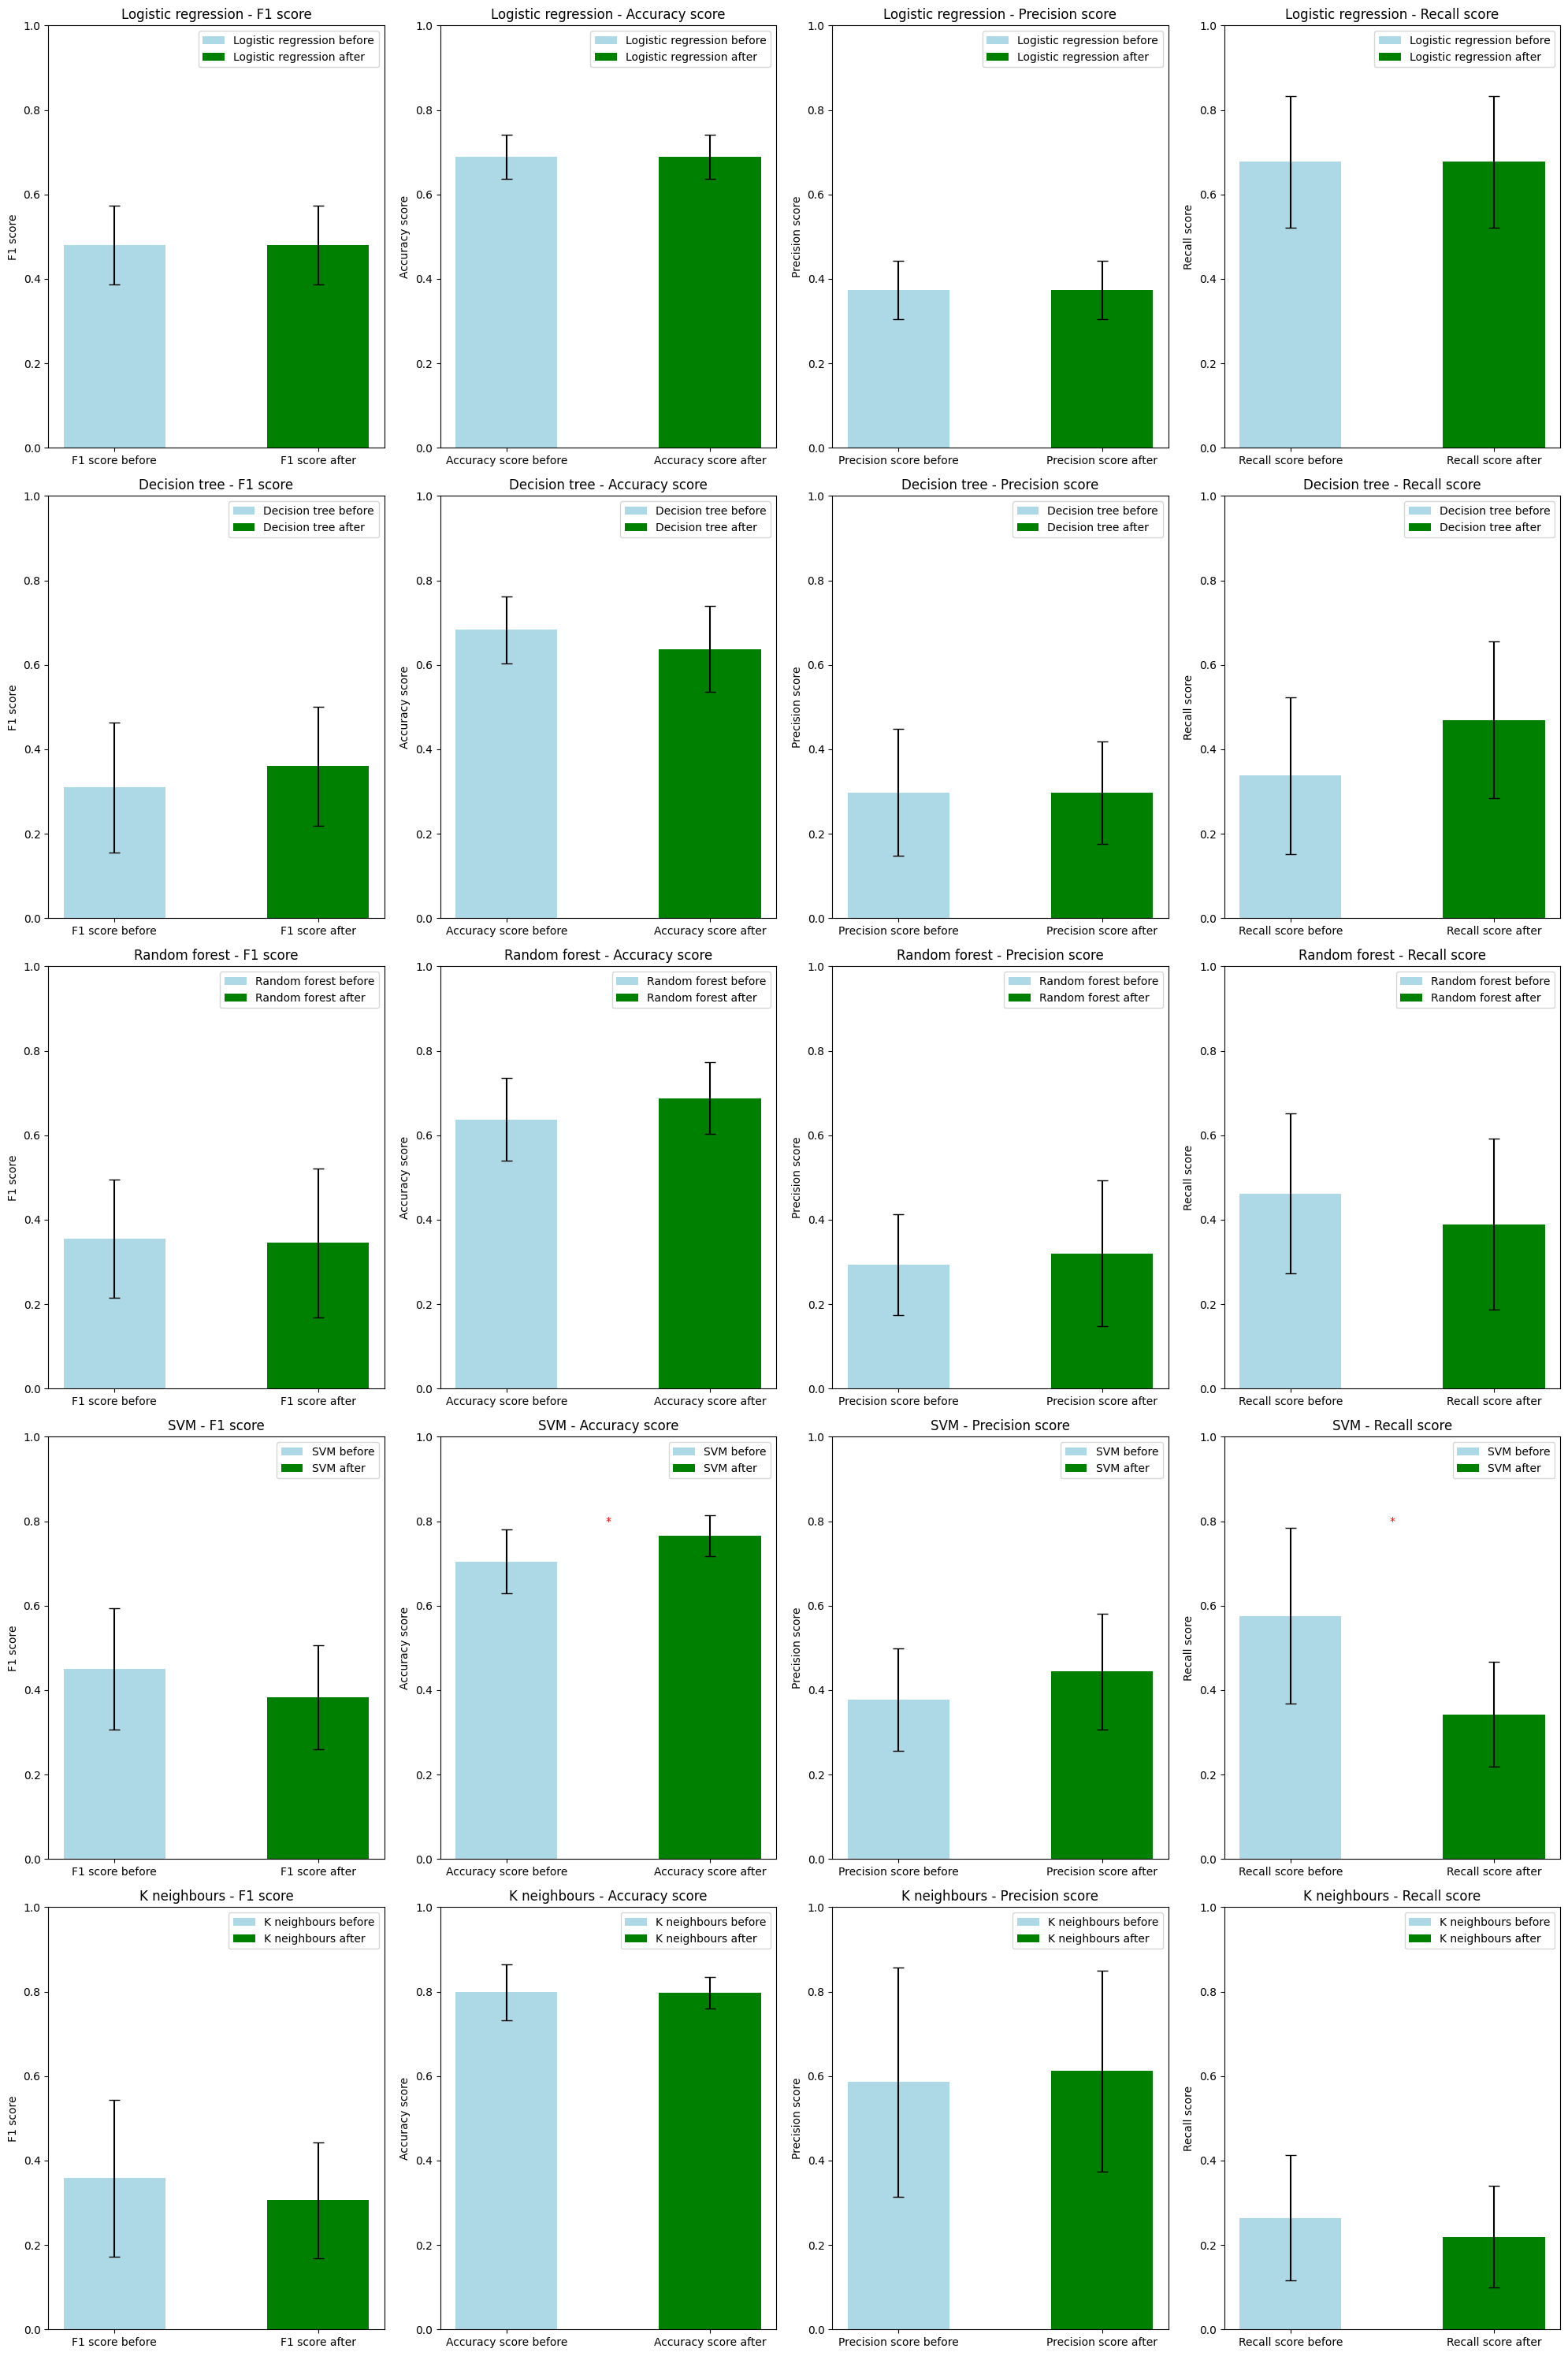

In [167]:

def modelBarcharts():
    keys = [1,2,3,4,5]
    algorithmName = ["Logistic regression", "Decision tree","Random forest","SVM", "K neighbours"]
    columnNames=['F1 score','Accuracy score','Precision score', 'Recall score']

    fig, axs = plt.subplots(len(keys), 4, figsize=(20, 30)) 
    # fig.suptitle('Model performance scores before and after Hyperparameter tuning')

    for i, key in enumerate(algorithmName):
        for j in range(4):
            df1 = before[i]
            df2 = after[key]
            value_column = columnNames[j]

            mean1 = df1[value_column].mean()
            mean2 = df2[value_column].mean()
            std1 = df1[value_column].std()
            std2 = df2[value_column].std()

            p = stats.ttest_ind(df1[value_column], df2[value_column]).pvalue
            if (p < 0.05):
                star = '*'
            else:
                star = ''

            positions = [1, 2] 
            axs[i, j].bar(positions[0], mean1, color='lightblue', yerr=std1, capsize=5, label=f'{key} before', width=0.5)
            axs[i, j].bar(positions[1], mean2, color='green', yerr=std2, capsize=5, label=f'{key} after', width=0.5)
            axs[i, j].set_xticks(positions)
            axs[i, j].set_xticklabels([f'{value_column} before', f'{value_column} after'])
            axs[i, j].set_ylabel(value_column)
            axs[i, j].legend()
            axs[i, j].set_title(f'{key} - {value_column}') 
            axs[i, j].set_ylim(0, 1)
            axs[i, j].text(1.5, 0.8, star, ha='center', va='center', color='red')
            
    plt.tight_layout() 
    plt.show()


modelBarcharts()